In [1]:
import heapq
import time
import random

# =====================================================================
# SECTION 1: ROUTE PLANNING MODULE (DIJKSTRA)
# =====================================================================

def calculate_dijkstra(graph, source, destination):
    """Core Dijkstra's algorithm logic with intermediate distance traces."""
    distances = {node: float('inf') for node in graph}
    distances[source] = 0
    predecessors = {node: None for node in graph}
    pq = [(0, source)]
    
    print("\n--- Intermediate Distance Updates ---")
    
    while pq:
        current_distance, current_node = heapq.heappop(pq)
        
        if current_distance > distances[current_node]:
            continue
            
        print(f"Visiting Node: {current_node} (Current Shortest Distance: {current_distance})")
        
        if current_node == destination:
            break
        
        for neighbor, weight in graph[current_node].items():
            distance = current_distance + weight
            
            if distance < distances[neighbor]:
                old_dist = distances[neighbor]
                distances[neighbor] = distance
                predecessors[neighbor] = current_node
                heapq.heappush(pq, (distance, neighbor))
                print(f"  -> Updated neighbor {neighbor}: {old_dist} -> {distance} via {current_node}")
                
    if distances[destination] == float('inf'):
        return None, float('inf')

    path = []
    current = destination
    while current is not None:
        path.append(current)
        current = predecessors[current]
    path.reverse()
    
    return path, distances[destination]


def run_route_planner():
    """Dijkstra Interactive Execution Engine."""
    print("\n==================================================")
    print("      RUNNING DIJKSTRA ROUTE PLANNER              ")
    print("==================================================")
    use_custom = input("Do you want to enter custom input? (yes/no): ").strip().lower()
    
    if use_custom == "yes":
        print("\n--- Enter Graph Details ---")
        print("Format for edges: 'Node1 Node2 Weight' (e.g., A B 5). Type 'done' when finished.")
        graph = {}
        while True:
            edge_input = input("Enter edge (or 'done'): ").strip()
            if edge_input.lower() == 'done':
                break
                
            parts = edge_input.split()
            if len(parts) != 3:
                print("Invalid format. Use: 'Node1 Node2 Weight'.")
                continue
                
            u, v, w_str = parts
            try:
                w = float(w_str)
                if w < 0:
                    print("Error: Dijkstra does not support negative weights.")
                    continue
            except ValueError:
                print("Invalid weight numeric type.")
                continue
                
            graph.setdefault(u, {})[v] = w
            graph.setdefault(v, {})[u] = w
        
        source = input("Enter source location: ").strip()
        destination = input("Enter destination location: ").strip()
        
    else:
        print("\n--- Running with Example Graph ---")
        graph = {
            'A': {'B': 4, 'C': 2},
            'B': {'A': 4, 'C': 1, 'D': 5},
            'C': {'A': 2, 'B': 1, 'D': 8, 'E': 10},
            'D': {'B': 5, 'C': 8, 'E': 2, 'Z': 6},
            'E': {'C': 10, 'D': 2, 'Z': 3},
            'Z': {'D': 6, 'E': 3}
        }
        source = 'A'
        destination = 'Z'
        print(f"Source: {source}\nDestination: {destination}\nGraph Layout:")
        for node, edges in graph.items():
            print(f"  {node} connects to: {dict(edges)}")

    if not graph or source not in graph or destination not in graph:
        print("\nError: Empty graph or invalid source/destination references.")
        return
        
    if source == destination:
        print("\n--- Route Planning Summary ---")
        print(f"Shortest Route: {source}\nTotal Travel Cost: 0.0")
        return

    path, total_cost = calculate_dijkstra(graph, source, destination)

    if path is None:
        print(f"\nNo route found between {source} and {destination}.")
    else:
        print("\n--- Route Planning Summary ---")
        print(f"Shortest Route: {' -> '.join(path)}")
        print(f"Total Travel Cost: {total_cost}")


# =====================================================================
# SECTION 2: INFRASTRUCTURE PLANNING & COMPARATIVE ANALYSIS
# =====================================================================

class DisjointSet:
    """Helper structure for Kruskal's Algorithm."""
    def __init__(self, vertices):
        self.parent = {v: v for v in vertices}
        self.rank = {v: 0 for v in vertices}

    def find(self, item):
        if self.parent[item] != item:
            self.parent[item] = self.find(self.parent[item])
        return self.parent[item]

    def union(self, set1, set2):
        root1 = self.find(set1)
        root2 = self.find(set2)
        if root1 != root2:
            if self.rank[root1] > self.rank[root2]:
                self.parent[root2] = root1
            else:
                self.parent[root1] = root2
                if self.rank[root1] == self.rank[root2]:
                    self.rank[root2] += 1
            return True
        return False


def prim_mst(graph):
    """Generates MST using Prim's algorithm."""
    start_node = next(iter(graph.keys()))
    visited = {start_node}
    mst_edges = []
    total_cost = 0
    
    # Priority Queue structures: (weight, active_node, target_neighbor)
    pq = []
    for neighbor, weight in graph[start_node].items():
        heapq.heappush(pq, (weight, start_node, neighbor))
        
    while pq:
        weight, u, v = heapq.heappop(pq)
        if v not in visited:
            visited.add(v)
            mst_edges.append((u, v, weight))
            total_cost += weight
            for neighbor, n_weight in graph[v].items():
                if neighbor not in visited:
                    heapq.heappush(pq, (n_weight, v, neighbor))
                    
    return mst_edges, total_cost


def kruskal_mst(graph):
    """Generates MST using Kruskal's algorithm."""
    edges = []
    seen = set()
    for u in graph:
        for v, weight in graph[u].items():
            if (v, u) not in seen:
                edges.append((weight, u, v))
                seen.add((u, v))
                
    edges.sort() # Sort edges dynamically by weight
    ds = DisjointSet(graph.keys())
    mst_edges = []
    total_cost = 0
    
    for weight, u, v in edges:
        if ds.union(u, v):
            mst_edges.append((u, v, weight))
            total_cost += weight
            
    return mst_edges, total_cost


def generate_random_connected_graph(num_vertices, num_edges):
    """Generates test networks to perform experiments on multiple sizes."""
    graph = {i: {} for i in range(num_vertices)}
    
    # Guarantee basic connectivity spanning path first
    for i in range(1, num_vertices):
        weight = round(random.uniform(1.0, 20.0), 2)
        graph[i-1][i] = weight
        graph[i][i-1] = weight
        
    # Append random remaining edges to reach target density
    current_edges = num_vertices - 1
    while current_edges < num_edges:
        u = random.randint(0, num_vertices - 1)
        v = random.randint(0, num_vertices - 1)
        if u != v and v not in graph[u]:
            weight = round(random.uniform(1.0, 20.0), 2)
            graph[u][v] = weight
            graph[v][u] = weight
            current_edges += 1
            
    return graph


def run_infrastructure_experiments():
    """Runs structural execution timing across varying layout scaling sizes."""
    print("\n==================================================")
    print("   RUNNING MST COMPARATIVE EXPERIMENT HARNESS      ")
    print("==================================================")
    
    # Test criteria layout matrices: (Vertices, Edges)
    test_sizes = [(50, 150), (250, 1000), (750, 4000)]
    
    print(f"{'Vertices':<10}{'Edges':<10}{'Prim Time (s)':<18}{'Kruskal Time (s)':<18}{'MST Costs Match?'}")
    print("-" * 70)
    
    for v_count, e_count in test_sizes:
        exp_network = generate_random_connected_graph(v_count, e_count)
        
        # Benchmarking Prim's Performance
        t0 = time.perf_counter()
        _, prim_cost = prim_mst(exp_network)
        t1 = time.perf_counter()
        prim_time = t1 - t0
        
        # Benchmarking Kruskal's Performance
        t2 = time.perf_counter()
        _, kruskal_cost = kruskal_mst(exp_network)
        t3 = time.perf_counter()
        kruskal_time = t3 - t2
        
        # Verify optimization validity checks
        match = "Yes" if abs(prim_cost - kruskal_cost) < 1e-4 else "No"
        
        print(f"{v_count:<10}{e_count:<10}{prim_time:<18.6f}{kruskal_time:<18.6f}{match}")

    print("\n--- Theoretical Complexity Analysis Summary ---")
    print("• Prim's Algorithm (Adjacency List + Heap): O(E log V)")
    print("  -> Optimized for Dense networks due to immediate neighborhood extractions.")
    print("• Kruskal's Algorithm (Sort + Disjoint Set): O(E log E) or O(E log V)")
    print("  -> Optimized for Sparse networks because sorting operations execute efficiently.")


# =====================================================================
# MAIN DRIVER CONTROL
# =====================================================================
if __name__ == "__main__":
    # Part 1 Requirements Execution
    run_route_planner()
    
    # Part 2 Requirements Execution
    run_infrastructure_experiments()


      RUNNING DIJKSTRA ROUTE PLANNER              


Do you want to enter custom input? (yes/no):  no



--- Running with Example Graph ---
Source: A
Destination: Z
Graph Layout:
  A connects to: {'B': 4, 'C': 2}
  B connects to: {'A': 4, 'C': 1, 'D': 5}
  C connects to: {'A': 2, 'B': 1, 'D': 8, 'E': 10}
  D connects to: {'B': 5, 'C': 8, 'E': 2, 'Z': 6}
  E connects to: {'C': 10, 'D': 2, 'Z': 3}
  Z connects to: {'D': 6, 'E': 3}

--- Intermediate Distance Updates ---
Visiting Node: A (Current Shortest Distance: 0)
  -> Updated neighbor B: inf -> 4 via A
  -> Updated neighbor C: inf -> 2 via A
Visiting Node: C (Current Shortest Distance: 2)
  -> Updated neighbor B: 4 -> 3 via C
  -> Updated neighbor D: inf -> 10 via C
  -> Updated neighbor E: inf -> 12 via C
Visiting Node: B (Current Shortest Distance: 3)
  -> Updated neighbor D: 10 -> 8 via B
Visiting Node: D (Current Shortest Distance: 8)
  -> Updated neighbor E: 12 -> 10 via D
  -> Updated neighbor Z: inf -> 14 via D
Visiting Node: E (Current Shortest Distance: 10)
  -> Updated neighbor Z: 14 -> 13 via E
Visiting Node: Z (Current Short


      RUNNING DIJKSTRA ROUTE PLANNER              

--- Running with Example Graph ---
Source: A
Destination: Z
Graph Layout:
  A connects to: {'B': 4, 'C': 2}
  B connects to: {'A': 4, 'C': 1, 'D': 5}
  C connects to: {'A': 2, 'B': 1, 'D': 8, 'E': 10}
  D connects to: {'B': 5, 'C': 8, 'E': 2, 'Z': 6}
  E connects to: {'C': 10, 'D': 2, 'Z': 3}
  Z connects to: {'D': 6, 'E': 3}

--- Intermediate Distance Updates ---
Visiting Node: A (Current Shortest Distance: 0)
  -> Updated neighbor B: inf -> 4 via A
  -> Updated neighbor C: inf -> 2 via A
Visiting Node: C (Current Shortest Distance: 2)
  -> Updated neighbor B: 4 -> 3 via C
  -> Updated neighbor D: inf -> 10 via C
  -> Updated neighbor E: inf -> 12 via C
Visiting Node: B (Current Shortest Distance: 3)
  -> Updated neighbor D: 10 -> 8 via B
Visiting Node: D (Current Shortest Distance: 8)
  -> Updated neighbor E: 12 -> 10 via D
  -> Updated neighbor Z: inf -> 14 via D
Visiting Node: E (Current Shortest Distance: 10)
  -> Updated neighb

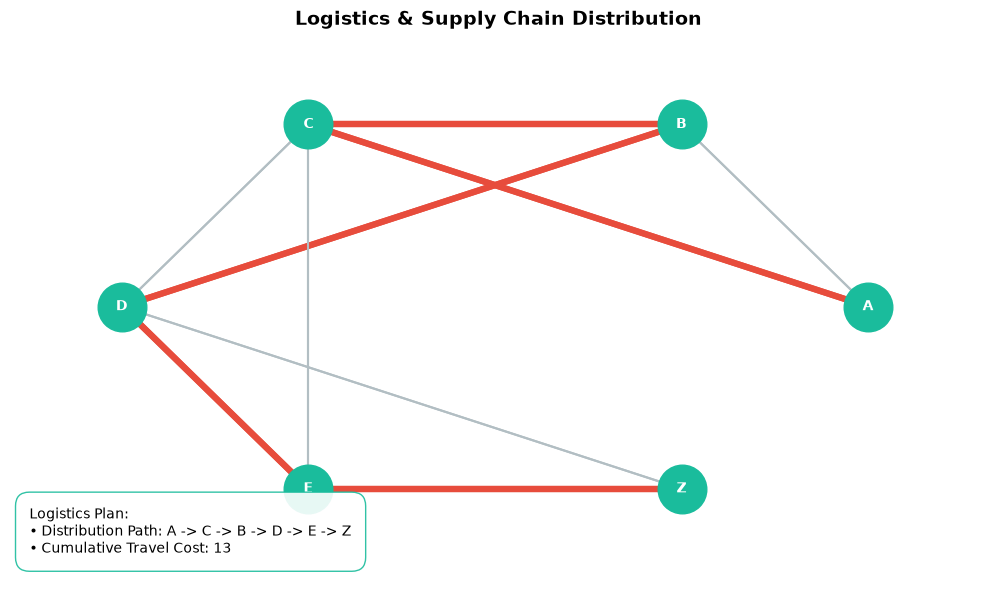


   RUNNING MST COMPARATIVE EXPERIMENT HARNESS      
Vertices  Edges     Prim Time (s)     Kruskal Time (s)  MST Costs Match?
----------------------------------------------------------------------
50        150       0.000446          0.001409          Yes
250       1000      0.002139          0.003762          Yes
750       4000      0.012673          0.018570          Yes

--- Theoretical Complexity Analysis Summary ---
• Prim's Algorithm (Adjacency List + Heap): O(E log V)
  -> Optimized for Dense networks due to immediate neighborhood extractions.
• Kruskal's Algorithm (Sort + Disjoint Set): O(E log E) or O(E log V)
  -> Optimized for Sparse networks because sorting operations execute efficiently.


In [9]:
import heapq
import time
import random
import matplotlib
import matplotlib.pyplot as plt
import math

matplotlib.use('inline') if hasattr(matplotlib, 'use') else None

def calculate_dijkstra(graph, source, destination):
    distances = {node: float('inf') for node in graph}
    distances[source] = 0
    predecessors = {node: None for node in graph}
    pq = [(0, source)]
    
    print("\n--- Intermediate Distance Updates ---")
    
    while pq:
        current_distance, current_node = heapq.heappop(pq)
        
        if current_distance > distances[current_node]:
            continue
            
        print(f"Visiting Node: {current_node} (Current Shortest Distance: {current_distance})")
        
        if current_node == destination:
            break
        
        for neighbor, weight in graph[current_node].items():
            distance = current_distance + weight
            
            if distance < distances[neighbor]:
                old_dist = distances[neighbor]
                distances[neighbor] = distance
                predecessors[neighbor] = current_node
                heapq.heappush(pq, (distance, neighbor))
                print(f"  -> Updated neighbor {neighbor}: {old_dist} -> {distance} via {current_node}")
                
    if distances[destination] == float('inf'):
        return None, float('inf')

    path = []
    current = destination
    while current is not None:
        path.append(current)
        current = predecessors[current]
    path.reverse()
    
    return path, distances[destination]

def visualize_logistics_hub(graph, active_path, total_cost):
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.set_title(" Logistics & Supply Chain Distribution", fontsize=14, fontweight='bold')
    
    nodes = list(graph.keys())
    num_nodes = len(nodes)
    pos = {}
    for idx, node in enumerate(nodes):
        angle = 2 * math.pi * idx / num_nodes
        pos[node] = (math.cos(angle), math.sin(angle))
        
    for u in graph:
        for v, weight in graph[u].items():
            if u not in pos or v not in pos:
                continue
            x1, y1 = pos[u]
            x2, y2 = pos[v]
            
            is_on_path = False
            if active_path:
                for i in range(len(active_path) - 1):
                    if (active_path[i] == u and active_path[i+1] == v) or (active_path[i] == v and active_path[i+1] == u):
                        is_on_path = True
                        break
                        
            if is_on_path:
                ecolor = '#e74c3c'
                ewidth = 4.5
            else:
                ecolor = '#b2bec3'
                ewidth = 1.5
                
            dx = x2 - x1
            dy = y2 - y1
            length = math.sqrt(dx*dx + dy*dy)
            if length > 0:
                ax.plot([x1, x2], [y1, y2], color=ecolor, lw=ewidth)
                
    for node, (x, y) in pos.items():
        ax.plot(x, y, marker='o', markersize=35, color='#1abc9c', linestyle='None')
        ax.text(x, y, str(node), color='white', ha='center', va='center', fontweight='bold', fontsize=10)
        
    path_string = " -> ".join(active_path) if active_path else "None"
    info_text = f"Logistics Plan:\n• Distribution Path: {path_string}\n• Cumulative Travel Cost: {total_cost}"
    ax.text(0.02, 0.05, info_text, transform=ax.transAxes, 
            bbox=dict(facecolor='white', alpha=0.9, edgecolor='#1abc9c', boxstyle='round,pad=1'))
    
    ax.set_xlim(-1.3, 1.3)
    ax.set_ylim(-1.3, 1.3)
    ax.axis('off')
    plt.tight_layout()
    plt.show()

def run_route_planner():
    print("\n==================================================")
    print("      RUNNING DIJKSTRA ROUTE PLANNER              ")
    print("==================================================")
    
    print("\n--- Running with Example Graph ---")
    graph = {
        'A': {'B': 4, 'C': 2},
        'B': {'A': 4, 'C': 1, 'D': 5},
        'C': {'A': 2, 'B': 1, 'D': 8, 'E': 10},
        'D': {'B': 5, 'C': 8, 'E': 2, 'Z': 6},
        'E': {'C': 10, 'D': 2, 'Z': 3},
        'Z': {'D': 6, 'E': 3}
    }
    source = 'A'
    destination = 'Z'
    print(f"Source: {source}\nDestination: {destination}\nGraph Layout:")
    for node, edges in graph.items():
        print(f"  {node} connects to: {dict(edges)}")

    path, total_cost = calculate_dijkstra(graph, source, destination)

    if path is None:
        print(f"\nNo route found between {source} and {destination}.")
    else:
        print("\n--- Route Planning Summary ---")
        print(f"Shortest Route: {' -> '.join(path)}")
        print(f"Total Travel Cost: {total_cost}")
        visualize_logistics_hub(graph, path, total_cost)

class DisjointSet:
    def __init__(self, vertices):
        self.parent = {v: v for v in vertices}
        self.rank = {v: 0 for v in vertices}

    def find(self, item):
        if self.parent[item] != item:
            self.parent[item] = self.find(self.parent[item])
        return self.parent[item]

    def union(self, set1, set2):
        root1 = self.find(set1)
        root2 = self.find(set2)
        if root1 != root2:
            if self.rank[root1] > self.rank[root2]:
                self.parent[root2] = root1
            else:
                self.parent[root1] = root2
                if self.rank[root1] == self.rank[root2]:
                    self.rank[root2] += 1
            return True
        return False

def prim_mst(graph):
    start_node = next(iter(graph.keys()))
    visited = {start_node}
    mst_edges = []
    total_cost = 0
    
    pq = []
    for neighbor, weight in graph[start_node].items():
        heapq.heappush(pq, (weight, start_node, neighbor))
        
    while pq:
        weight, u, v = heapq.heappop(pq)
        if v not in visited:
            visited.add(v)
            mst_edges.append((u, v, weight))
            total_cost += weight
            for neighbor, n_weight in graph[v].items():
                if neighbor not in visited:
                    heapq.heappush(pq, (n_weight, v, neighbor))
                    
    return mst_edges, total_cost

def kruskal_mst(graph):
    edges = []
    seen = set()
    for u in graph:
        for v, weight in graph[u].items():
            if (v, u) not in seen:
                edges.append((weight, u, v))
                seen.add((u, v))
                
    edges.sort()
    ds = DisjointSet(graph.keys())
    mst_edges = []
    total_cost = 0
    
    for weight, u, v in edges:
        if ds.union(u, v):
            mst_edges.append((u, v, weight))
            total_cost += weight
            
    return mst_edges, total_cost

def generate_random_connected_graph(num_vertices, num_edges):
    graph = {i: {} for i in range(num_vertices)}
    
    for i in range(1, num_vertices):
        weight = round(random.uniform(1.0, 20.0), 2)
        graph[i-1][i] = weight
        graph[i][i-1] = weight
        
    current_edges = num_vertices - 1
    while current_edges < num_edges:
        u = random.randint(0, num_vertices - 1)
        v = random.randint(0, num_vertices - 1)
        if u != v and v not in graph[u]:
            weight = round(random.uniform(1.0, 20.0), 2)
            graph[u][v] = weight
            graph[v][u] = weight
            current_edges += 1
            
    return graph

def run_infrastructure_experiments():
    print("\n==================================================")
    print("   RUNNING MST COMPARATIVE EXPERIMENT HARNESS      ")
    print("==================================================")
    
    test_sizes = [(50, 150), (250, 1000), (750, 4000)]
    
    print(f"{'Vertices':<10}{'Edges':<10}{'Prim Time (s)':<18}{'Kruskal Time (s)':<18}{'MST Costs Match?'}")
    print("-" * 70)
    
    for v_count, e_count in test_sizes:
        exp_network = generate_random_connected_graph(v_count, e_count)
        
        t0 = time.perf_counter()
        _, prim_cost = prim_mst(exp_network)
        t1 = time.perf_counter()
        prim_time = t1 - t0
        
        t2 = time.perf_counter()
        _, kruskal_cost = kruskal_mst(exp_network)
        t3 = time.perf_counter()
        kruskal_time = t3 - t2
        
        match = "Yes" if abs(prim_cost - kruskal_cost) < 1e-4 else "No"
        
        print(f"{v_count:<10}{e_count:<10}{prim_time:<18.6f}{kruskal_time:<18.6f}{match}")

    print("\n--- Theoretical Complexity Analysis Summary ---")
    print("• Prim's Algorithm (Adjacency List + Heap): O(E log V)")
    print("  -> Optimized for Dense networks due to immediate neighborhood extractions.")
    print("• Kruskal's Algorithm (Sort + Disjoint Set): O(E log E) or O(E log V)")
    print("  -> Optimized for Sparse networks because sorting operations execute efficiently.")

run_route_planner()
run_infrastructure_experiments()